## Implementing algorithm 1 from the paper. 
Computing omega points for the 3vs1 case
including the functions to check if points are in a good position 


## Todo: 
- look  out for conflicts between modules and modules_old
- Can we add function to check if 3 pts 


In [1]:
import gudhi
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import matplotlib
from math import cos, sin, pi, atan
import itertools

import numpy.linalg

## for checking if in convex hull
import scipy.spatial
from scipy.optimize import linprog

import sys 
sys.path.append('../Code/')
import modules as mod
import csv

import omega_pts as omega
# This reloads external modules every time a cell is run
# so we don't have to reboot kernel every time we modify classes.py
%load_ext autoreload
%autoreload 2

## Hardcoded data

In [2]:
# # here we define four critical values to check. 
# # later we'll want to import these 4 at a time from a bigger set, but for now we just hardcode them.
# c1 = mod.critical_val((0,0), 0)
# c2 = mod.critical_val((0,1), 0)
# c3 = mod.critical_val((1,0),0)
# c4 = mod.critical_val((1,1),0)
# CritPts = [c1,c2,c3,c4]
# print(CritPts)
# omega.algo_3vs1(CritPts)

## Examples from the paper

### Example 2.13, figure 3

$M = [0,7)\times [0,8) \cup [0,7)\times [4,11)$ and $N = [0,7)\times [0,11) \cup [0,7)\times [4,8)$

In [3]:

c1 = mod.critical_val((0,0), 0)
c2 = mod.critical_val((7,0), 0)
c3 = mod.critical_val((0,4),0)
c4 = mod.critical_val((7,4),0)
c5 = mod.critical_val((0,8),0)
c6 = mod.critical_val((7,8),0)
c7 = mod.critical_val((0,11),0)
c8 = mod.critical_val((7,11),0)


d1 = mod.critical_val((0,0), 1)
d2 = mod.critical_val((7,0), 1)
d3 = mod.critical_val((0,4),1)
d4 = mod.critical_val((7,4),1)
d5 = mod.critical_val((0,8),1)
d6 = mod.critical_val((7,8),1)
d7 = mod.critical_val((0,11),1)
d8 = mod.critical_val((7,11),1)

#CritPts = [c1,c2,c3,c4,c5,c6,c7,c8,d1,d2,d3,d4,d5,d6,d7,d8]
CritPts = [c1,c2,c3,c4,c5,c7,d1,d2,d3,d4,d5,d7]



## rectangle 0 

In [4]:
Pts =[]
Dict_pts = [["omega_pts", "x","u","v","w","eta","delta"]]
set_of_points = set({})
length = len(CritPts)

for a in range(length): 
    for b in range(a+1,length):
        for c in range(b+1,length):
            for d in range(c, length):
                if omega.check_3distinct([CritPts[a],CritPts[b],CritPts[c],CritPts[d]]):
                    pts, dict_pts = omega.algo_3vs1([CritPts[a],CritPts[b],CritPts[c],CritPts[d]])
                    Pts += pts
                    # a first attempt to get rid of duplicates
                    # this should be moved to the omega file
                    for p in range(len(pts)):
                        if pts[p] not in set_of_points:
                            set_of_points.add(pts[p])
                            Dict_pts += [dict_pts[p]]

                    

print('**********')
print("Computed {} points (with duplicates)".format(len(Pts)))

# # checking a weird number discrep; uncomment later
Pts = list(set(Pts))
print("Without duplicates {}".format(len(Pts)))

#Dict_pts.sort() 
#new_pts= list(k for k,_ in itertools.groupby(k))

# w+ option overwrites file each time (good thing)
with open('ExamplePaper-2_13_discard_omega.csv', 'w+', newline='') as file: 
    writer = csv.writer(file)
    writer.writerows(Dict_pts)                    
            

../Code/omega_pts.py:27: OptimizeWarning: A_eq does not appear to be of full row rank. To improve performance, check the problem formulation for redundant equality constraints.
  lp = linprog(c, A_eq=A, b_eq=b, )


The omega point (7, 8.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 4) is 0)
u = (parent module of (0, 4) is 0)
v = (parent module of (0, 0) is 0)
****************
The omega point (7, 8.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 4) is 0)
u = (parent module of (0, 4) is 0)
v = (parent module of (0, 0) is 0)
****************
Computed 0 omega points with duplicates
Without duplicates: 0
The omega point (7, 0.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 0) is 0)
u = (parent module of (7, 4) is 0)
v = (parent module of (0, 4) is 0)
****************
The omega point (7, 8.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 4) is 0)
u = (parent module of (7, 4) is 0)
v = (parent module of (0, 0) is 0)
****************
The omega point (7, 0.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (7, 4) is 0)
u = (parent module o

../Code/omega_pts.py:27: OptimizeWarning: Solving system with option 'cholesky':True failed. It is normal for this to happen occasionally, especially as the solution is approached. However, if you see this frequently, consider setting option 'cholesky' to False.
  lp = linprog(c, A_eq=A, b_eq=b, )
../Code/omega_pts.py:27: OptimizeWarning: Solving system with option 'sym_pos':True failed. It is normal for this to happen occasionally, especially as the solution is approached. However, if you see this frequently, consider setting option 'sym_pos' to False.
  lp = linprog(c, A_eq=A, b_eq=b, )
../Code/omega_pts.py:27: OptimizeWarning: Solving system with option 'sym_pos':False failed. This may happen occasionally, especially as the solution is approached. However, if you see this frequently, your problem may be numerically challenging. If you cannot improve the formulation, consider setting 'lstsq' to True. Consider also setting `presolve` to True, if it is not already.
  lp = linprog(c, A_

Computed 1 omega points with duplicates
Without duplicates: 1
The omega point (7, -4.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (7, 4) is 0)
u = (parent module of (7, 4) is 1)
v = (parent module of (0, 0) is 0)
****************
The omega point (7, 2.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (7, 4) is 1)
u = (parent module of (7, 4) is 0)
v = (parent module of (0, 0) is 0)
****************
Computed 0 omega points with duplicates
Without duplicates: 0
The omega point (7, 8.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 0) is 0)
u = (parent module of (0, 8) is 1)
v = (parent module of (7, 4) is 0)
****************
The omega point (7, -12.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (7, 4) is 0)
u = (parent module of (0, 8) is 1)
v = (parent module of (0, 0) is 0)
****************
The omega point (7, 10.0) was generated from
x = (parent module of (7

In [5]:
# # print(set_of_points)
# # print(len(set_of_points))
# print(len(Pts))
# print(len(Dict_pts))
# setpts = set(Pts)
# print(len(setpts), "\n")

# print(Pts, "\n")
# print(setpts, "\n")
# print(Dict_pts)

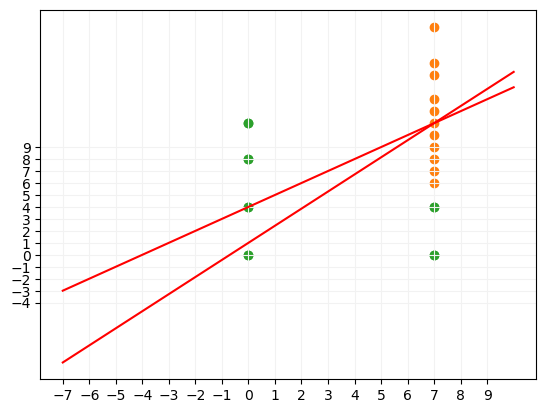

In [8]:
fig = plt.figure()
ax = fig.gca()

for pt in Pts:
    matplotlib.pyplot.scatter(pt[0], pt[1],c='C1')
for crit in CritPts:
    matplotlib.pyplot.scatter(crit.coords[0], crit.coords[1],c='C2')
    
ax.set_xticks(numpy.arange(-7,10, 1))
ax.set_yticks(numpy.arange(-4, 10, 1))

# plot line of equation y = 10/7 x +1 
x = np.linspace(-7, 10, 100)
y = 10/7*x + 1
plt.plot(x, y, '-r', label='y=10/7x+1')

# plot linr of slope 1 thrrough (7,11) 
x = np.linspace(-7, 10, 100)
y = x + 4
plt.plot(x, y, '-r', label='y=x+4')



plt.grid(axis='both', color='0.95')



### Example 2.11

$M = [0,7)\times [0,7) \cup [0,7)\times [4,11)$ and $N = [0,7)\times [0,11) \cup [0,7)\times [4,7)$

In [9]:
c1 = mod.critical_val((0,0), 0)
c2 = mod.critical_val((7,0), 0)
c3 = mod.critical_val((0,4),0)
c4 = mod.critical_val((7,4),0)
c5 = mod.critical_val((0,7),0)
c6 = mod.critical_val((7,7),0)
c7 = mod.critical_val((0,11),0)
c8 = mod.critical_val((7,11),0)


d1 = mod.critical_val((0,0), 1)
d2 = mod.critical_val((7,0), 1)
d3 = mod.critical_val((0,4),1)
d4 = mod.critical_val((7,4),1)
d5 = mod.critical_val((0,7),1)
d6 = mod.critical_val((7,7),1)
d7 = mod.critical_val((0,11),1)
d8 = mod.critical_val((7,11),1)

#CritPts = [c1,c2,c3,c4,c5,c6,c7,c8,d1,d2,d3,d4,d5,d6,d7,d8]

CritPts = [c1,c2,c3,c4,c5,c7,d1,d2,d3,d4,d5,d7]



In [10]:
Pts =[]
Dict_pts = [["omega_pts", "x","u","v","w","eta","delta"]]
set_of_points = set({})
length = len(CritPts)

for a in range(length): 
    for b in range(a+1,length):
        for c in range(b+1,length):
            for d in range(c, length):
                if omega.check_3distinct([CritPts[a],CritPts[b],CritPts[c],CritPts[d]]):
                    pts, dict_pts = omega.algo_3vs1([CritPts[a],CritPts[b],CritPts[c],CritPts[d]])
                    Pts += pts
                    # a first attempt to get rid of duplicates
                    # this should be moved to the omega file
                    for p in range(len(pts)):
                        if pts[p] not in set_of_points:
                            set_of_points.add(pts[p])
                            Dict_pts += [dict_pts[p]]

                    

print('**********')
print("Computed {} points (with duplicates)".format(len(Pts)))

# # checking a weird number discrep; uncomment later
Pts = list(set(Pts))
print("Without duplicates {}".format(len(Pts)))

#Dict_pts.sort() 
#new_pts= list(k for k,_ in itertools.groupby(k))

# w+ option overwrites file each time (good thing)
with open('ExamplePaper-2_11_discard_omega.csv', 'w+', newline='') as file: 
    writer = csv.writer(file)
    writer.writerows(Dict_pts) 



# OLD: CAN PROBABLY DELETE

# Pts =[]
# Dict_pts = [["omega_pts", "x","u","v","w","eta","delta"]]


# for a in range(len(CritPts)): 
#     for b in range(a+1,len(CritPts)):
#         for c in range(b+1,len(CritPts)):
#             for d in range(c, len(CritPts)):
#                 if omega.check_3distinct([CritPts[a],CritPts[b],CritPts[c],CritPts[d]]):
#                     pts, dict_pts = omega.algo_3vs1([CritPts[a],CritPts[b],CritPts[c],CritPts[d]])
#                     Pts +=pts
#                     Dict_pts += dict_pts
# print('**********')
# print("Computed {} points (with duplicates)".format(len(Pts)))

# Pts = list(set(Pts))
# print("Without duplicates {}".format(len(Pts)))

# with open('ExamplePaper-2_11.csv', 'a', newline='') as file:  
#     writer = csv.writer(file)
#     writer.writerows(Dict_pts)                    
            


                    

The omega point (7, 8.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 4) is 0)
u = (parent module of (0, 4) is 0)
v = (parent module of (0, 0) is 0)
****************
The omega point (7, 8.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 4) is 0)
u = (parent module of (0, 4) is 0)
v = (parent module of (0, 0) is 0)
****************
Computed 0 omega points with duplicates
Without duplicates: 0
The omega point (7, 0.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 0) is 0)
u = (parent module of (7, 4) is 0)
v = (parent module of (0, 4) is 0)
****************
The omega point (7, 8.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 4) is 0)
u = (parent module of (7, 4) is 0)
v = (parent module of (0, 0) is 0)
****************
The omega point (7, 0.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (7, 4) is 0)
u = (parent module o

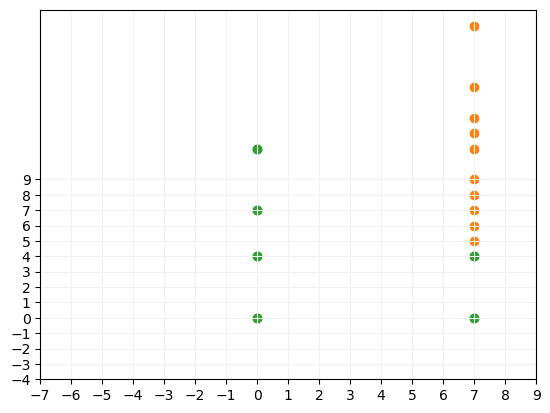

In [11]:
fig = plt.figure()
ax = fig.gca()

for pt in Pts:
    matplotlib.pyplot.scatter(pt[0], pt[1],c='C1')
for crit in CritPts:
    matplotlib.pyplot.scatter(crit.coords[0], crit.coords[1],c='C2')
    
ax.set_xticks(numpy.arange(-7,10, 1))
ax.set_yticks(numpy.arange(-4, 10, 1))

plt.grid(axis='both', color='0.95')

### Example 1
$M=[0,7]\times[0,8]$ and $N=[1,8]\times[1,9]$

In [12]:
c1 = mod.critical_val((0,0), 0)
c2 = mod.critical_val((7,0), 0)
c3 = mod.critical_val((0,8),0)
c4 = mod.critical_val((7,8),0)



d1 = mod.critical_val((1,1), 1)
d2 = mod.critical_val((8,1), 1)
d3 = mod.critical_val((1,9),1)
d4 = mod.critical_val((8,9),1)


#CritPts = [c1,c2,c3,c4,d1,d2,d3,d4]

CritPts = [c1,c2,c3,d1,d2,d3]


In [13]:
Pts =[]
Dict_pts = [["omega_pts", "x","u","v","w","eta","delta"]]
set_of_points = set({})
length = len(CritPts)

for a in range(length): 
    for b in range(a+1,length):
        for c in range(b+1,length):
            for d in range(c, length):
                if omega.check_3distinct([CritPts[a],CritPts[b],CritPts[c],CritPts[d]]):
                    pts, dict_pts = omega.algo_3vs1([CritPts[a],CritPts[b],CritPts[c],CritPts[d]])
                    Pts += pts
                    # a first attempt to get rid of duplicates
                    # this should be moved to the omega file
                    for p in range(len(pts)):
                        if pts[p] not in set_of_points:
                            set_of_points.add(pts[p])
                            Dict_pts += [dict_pts[p]]

                    

print('**********')
print("Computed {} points (with duplicates)".format(len(Pts)))

# # checking a weird number discrep; uncomment later
Pts = list(set(Pts))
print("Without duplicates {}".format(len(Pts)))

#Dict_pts.sort() 
#new_pts= list(k for k,_ in itertools.groupby(k))

# w+ option overwrites file each time (good thing)
with open('ExampleNotebook-1_discard_omega.csv', 'w+', newline='') as file: 
    writer = csv.writer(file)
    writer.writerows(Dict_pts) 


# OLD AND CAN PROBS DELETE
# Pts =[]
# Dict_pts = [["omega_pts", "x","u","v","w","eta","delta"]]


# for a in range(len(CritPts)): 
#     for b in range(a+1,len(CritPts)):
#         for c in range(b+1,len(CritPts)):
#             for d in range(c, len(CritPts)):
#                 if omega.check_3distinct([CritPts[a],CritPts[b],CritPts[c],CritPts[d]]):
#                     pts, dict_pts = omega.algo_3vs1([CritPts[a],CritPts[b],CritPts[c],CritPts[d]])
#                     Pts +=pts
#                     Dict_pts += dict_pts
# print('**********')
# print("Computed {} points (with duplicates)".format(len(Pts)))

# Pts = list(set(Pts))
# print("Without duplicates {}".format(len(Pts)))
# with open('ExampleNotebook-1.csv', 'a', newline='') as file:  
#     writer = csv.writer(file)
#     writer.writerows(Dict_pts)                    
            


                    

The omega point (7, 16.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 8) is 0)
u = (parent module of (0, 8) is 0)
v = (parent module of (0, 0) is 0)
****************
The omega point (7, 16.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 8) is 0)
u = (parent module of (0, 8) is 0)
v = (parent module of (0, 0) is 0)
****************
Computed 0 omega points with duplicates
Without duplicates: 0
The omega point (7, 14.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 0) is 0)
u = (parent module of (0, 8) is 0)
v = (parent module of (1, 1) is 1)
****************
The omega point (7, 10.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (0, 8) is 0)
u = (parent module of (1, 1) is 1)
v = (parent module of (0, 0) is 0)
****************
The omega point (7, 5.0) was generated from
x = (parent module of (7, 0) is 0)
w = (parent module of (1, 1) is 1)
u = (parent modu

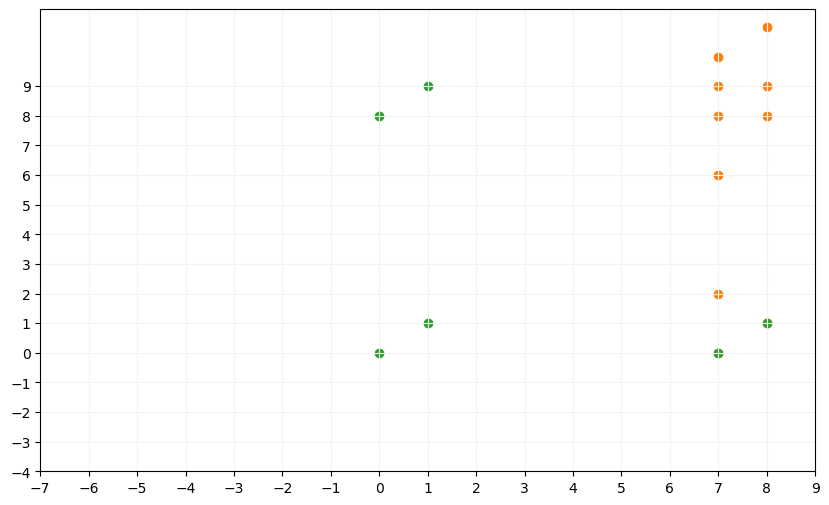

In [14]:
fig = plt.figure(figsize=(10,6))
ax = fig.gca()

for pt in Pts:
    matplotlib.pyplot.scatter(pt[0], pt[1],c='C1')
for crit in CritPts:
    matplotlib.pyplot.scatter(crit.coords[0], crit.coords[1],c='C2')
    
ax.set_xticks(numpy.arange(-7,10, 1))
ax.set_yticks(numpy.arange(-4, 10, 1))

plt.grid(axis='both', color='0.95')

### Example 2 
$M=[0,4]\times[0,4]$ and $N=[1,3]\times[0,4]$

Should have $(1,1),(2,2),(3,3)$ as $\Omega$-pts

In [22]:
c1 = mod.critical_val((0,0), 0)
c2 = mod.critical_val((4,0), 0)
c3 = mod.critical_val((0,4),0)
c4 = mod.critical_val((4,4),0)

d1 = mod.critical_val((1,0), 1)
d2 = mod.critical_val((3,0), 1)
d3 = mod.critical_val((1,4),1)
d4 = mod.critical_val((3,4),1)

#CritPts = [c1,c2,c3,c4,d1,d2,d3,d4]
CritPts = [c1,c2,c3,d1,d2,d3]

In [23]:
Pts =[]
Dict_pts = [["omega_pts", "x","u","v","w","eta","delta"]]
set_of_points = set({})
length = len(CritPts)

for a in range(length): 
    for b in range(a+1,length):
        for c in range(b+1,length):
            for d in range(c, length):
                if omega.check_3distinct([CritPts[a],CritPts[b],CritPts[c],CritPts[d]]):
                    pts, dict_pts = omega.algo_3vs1([CritPts[a],CritPts[b],CritPts[c],CritPts[d]])
                    Pts += pts
                    # a first attempt to get rid of duplicates
                    # this should be moved to the omega file
                    for p in range(len(pts)):
                        if pts[p] not in set_of_points:
                            set_of_points.add(pts[p])
                            Dict_pts += [dict_pts[p]]

                    

print('**********')
print("Computed {} points (with duplicates)".format(len(Pts)))

# # checking a weird number discrep; uncomment later
Pts = list(set(Pts))
print("Without duplicates {}".format(len(Pts)))

#Dict_pts.sort() 
#new_pts= list(k for k,_ in itertools.groupby(k))

# w+ option overwrites file each time (good thing)
with open('ExampleNotebook-2_discard_omega.csv', 'w+', newline='') as file: 
    writer = csv.writer(file)
    writer.writerows(Dict_pts) 

# OLD AND CAN DELETE, YES?
# Pts =[]
# Dict_pts = [["omega_pts", "x","u","v","w","eta","delta"]]


# for a in range(len(CritPts)): 
#     for b in range(a+1,len(CritPts)):
#         for c in range(b+1,len(CritPts)):
#             for d in range(c, len(CritPts)):
#                 if omega.check_3distinct([CritPts[a],CritPts[b],CritPts[c],CritPts[d]]):
#                     pts, dict_pts = omega.algo_3vs1([CritPts[a],CritPts[b],CritPts[c],CritPts[d]])
#                     Pts +=pts
#                     Dict_pts += dict_pts
# print('**********')
# print("Computed {} points (with duplicates)".format(len(Pts)))

# Pts = list(set(Pts))
# print("Without duplicates {}".format(len(Pts)))
# with open('ExampleNotebook-2.csv', 'a', newline='') as file:  
#     writer = csv.writer(file)
#     writer.writerows(Dict_pts)                    
            

The omega point (4, 8.0) was generated from
x = (parent module of (4, 0) is 0)
w = (parent module of (0, 4) is 0)
u = (parent module of (0, 4) is 0)
v = (parent module of (0, 0) is 0)
****************
The omega point (4, 8.0) was generated from
x = (parent module of (4, 0) is 0)
w = (parent module of (0, 4) is 0)
u = (parent module of (0, 4) is 0)
v = (parent module of (0, 0) is 0)
****************
Computed 0 omega points with duplicates
Without duplicates: 0
The omega point (4, 8.0) was generated from
x = (parent module of (4, 0) is 0)
w = (parent module of (0, 0) is 0)
u = (parent module of (0, 4) is 0)
v = (parent module of (1, 0) is 1)
****************
The omega point (4, 4.0) was generated from
x = (parent module of (4, 0) is 0)
w = (parent module of (0, 4) is 0)
u = (parent module of (1, 0) is 1)
v = (parent module of (0, 0) is 0)
****************
The omega point (4, 2.0) was generated from
x = (parent module of (4, 0) is 0)
w = (parent module of (1, 0) is 1)
u = (parent module o

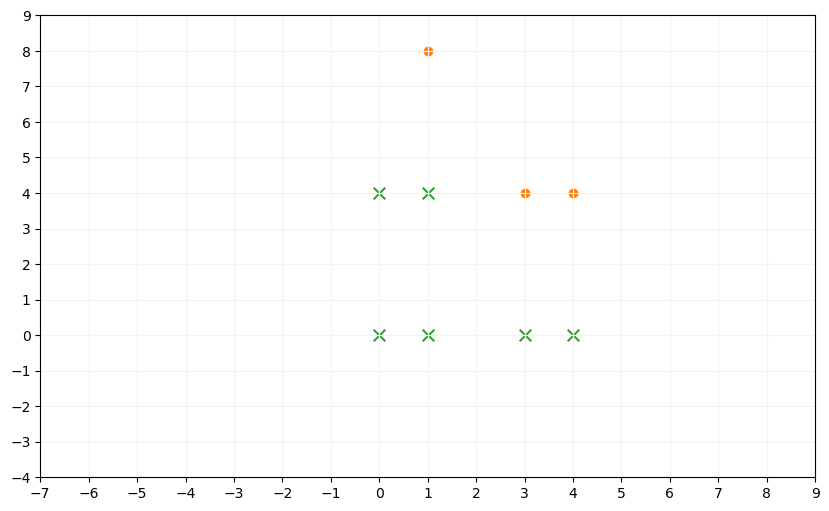

In [24]:
fig = plt.figure(figsize=(10,6))
ax = fig.gca()

for pt in Pts:
    matplotlib.pyplot.scatter(pt[0], pt[1],c='C1')
for crit in CritPts:
    matplotlib.pyplot.scatter(crit.coords[0], crit.coords[1],c='C2', marker = "x", s=70)
    
ax.set_xticks(numpy.arange(-7,10, 1))
ax.set_yticks(numpy.arange(-4, 10, 1))

plt.grid(axis='both', color='0.95')

###### remark: in this example we should not need the omega pts on the boundary of the support 

### without the closure 
in the examples above we ran the algorithm on $\overline{C_M}\sqcup\overline{C_N}$, here we try the last example above with $C_M\sqcup C_N$

In [ ]:
c1 = mod.critical_val((0,0), 0)
c2 = mod.critical_val((4,0), 0)
c3 = mod.critical_val((0,4),0)

d1 = mod.critical_val((1,0), 1)
d2 = mod.critical_val((3,0), 1)
d3 = mod.critical_val((1,4),1)

CritPts = [c1,c2,c3,d1,d2,d3]

In [ ]:
Pts =[]

for a in range(len(CritPts)): 
    for b in range(a+1,len(CritPts)):
        for c in range(b+1,len(CritPts)):
            for d in range(c, len(CritPts)):
                if omega.check_3distinct([CritPts[a],CritPts[b],CritPts[c],CritPts[d]]):
                    pts = omega.algo_3vs1([CritPts[a],CritPts[b],CritPts[c],CritPts[d]])
                    Pts +=pts
print('**********')
print("Computed {} points (with duplicates)".format(len(Pts)))

Pts = list(set(Pts))
print("Without duplicates {}".format(len(Pts)))

In [ ]:
fig = plt.figure(figsize=(10,6))
ax = fig.gca()

for pt in Pts:
    matplotlib.pyplot.scatter(pt[0], pt[1],c='C1')
for crit in CritPts:
    matplotlib.pyplot.scatter(crit.coords[0], crit.coords[1],c='C2', marker = "x", s=70)
    
ax.set_xticks(numpy.arange(-7,10, 1))
ax.set_yticks(numpy.arange(-4, 10, 1))

plt.grid(axis='both', color='0.95')

## Todo: 
- print out vaalue of eta and delta when printing the omegapts and the critical points it comes from
- add something to know when it was computed in terms of line of code

## Further analysis: 
    2. Can we determine which ones are usless
    3. compute distance and see which $\Omega$-pts are interesting --> we also dont have ALL the $\Omega$-pts because we only implemented one part of the entire algo to compute the 3vs1 case and not the 2v2 cases

### IDEA: 

    omega-pts are center of symetries for bars hence they need to be in the support of the module 